### **Phase 1: 라이브러리 import 및 데이터 전처리**

In [2]:
# 데이터 로드 라이브러리 설치
!pip install -q pybaseball
!pip install -q faiss-cpu
!pip install -q tabpfn

# 데이터 수집 및 조작 라이브러리 호출
from pybaseball import statcast
import numpy as np
import pandas as pd

# 데이터 복사
import copy

# 시각화 라이브러리 호출
import matplotlib.pyplot as plt
import seaborn as sns

# 기타 라이브러리
import os
import time
from getpass import getpass

# 카테고리 변수 라벨 인코딩 및 스케일링
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

# 데이터 분할 및 전처리 파이프라인
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 모델링 라이브러리
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from tabpfn import TabPFNClassifier

# 평가 라이브러리
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

from sklearn.calibration import calibration_curve

# 딥러닝 / 기타
import torch
import torch.nn as nn
import torch.optim as optim
import faiss

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.1/426.1 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 449.7/449.7 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.6 MB/s eta 0:00:00


In [3]:
# 데이터 로드
%%capture
df_origin = statcast(start_dt='2025-03-18', end_dt='2025-09-28', verbose = False)

In [4]:
# 데이터 복제
df = copy.deepcopy(df_origin)

# 초기 필수 컬럼 추출
df = df[["hc_x", "hc_y", "launch_speed", "launch_angle", "events", "home_team"]].copy()

# 홈런 후보군 물리적 필터링
min_hr_speed = df.loc[df["events"] == "home_run", "launch_speed"].min()
min_hr_angle = df.loc[df["events"] == "home_run", "launch_angle"].min()
df = df[(df["launch_angle"] >= min_hr_angle) & (df["launch_speed"] >= min_hr_speed)].copy()

# 타깃 변수 이진 매핑
df["events"] = df["events"].map({"home_run": 1}).fillna(0).astype(int)

# 분사각도 연산
df[["hc_x", "hc_y"]] = df[["hc_x", "hc_y"]].astype(float)
dx = df["hc_x"] - 125.42
dy = 198.27 - df["hc_y"]
df["spray_angle"] = np.degrees(np.arctan(dx / dy)) * 0.75

# 좌표 데이터 제거
df = df.drop(columns=["hc_x", "hc_y"])

# 결측 데이터 제거
df = df.dropna(how="any").reset_index(drop=True)

# 구장 변수 라벨 인코딩
le = LabelEncoder()
df["home_team"] = le.fit_transform(df["home_team"])

# 최종 데이터셋 구성
df = df[["launch_speed", "launch_angle", "spray_angle", "home_team", "events"]]
print(df.head())

   launch_speed  launch_angle  spray_angle  home_team  events
0         101.9            56    27.498328          4       0
1         105.0            16    -9.570264          4       0
2          91.2            78    67.469681          4       0
3          91.5            15    -1.900040          4       0
4          92.2            27   -12.414566          4       0


### **Phase 2: 모델 학습 및 예측**

In [5]:
# 입력 피처 / 타깃 분리
features = ["launch_speed", "launch_angle", "spray_angle", "home_team"]
target = "events"

X = df[features].copy()
y = df[target].copy()

# home_team을 순서형 숫자가 아니라 명목형 변수로 인식시키기 위해 문자열 처리
X["home_team"] = X["home_team"].astype(str)

print(X.head())
print(y.value_counts(normalize=True))

   launch_speed  launch_angle  spray_angle home_team
0         101.9            56    27.498328         4
1         105.0            16    -9.570264         4
2          91.2            78    67.469681         4
3          91.5            15    -1.900040         4
4          92.2            27   -12.414566         4
events
0    0.858134
1    0.141866
Name: proportion, dtype: float64


In [6]:
# Train+Validation / Test 데이터 분리
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train / Validation 데이터 분리
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    random_state=42,
    stratify=y_trainval
)

# 데이터셋별 샘플 수와 홈런 비율 확인
print("Train:", X_train.shape, "HR rate:", y_train.mean())
print("Valid:", X_val.shape, "HR rate:", y_val.mean())
print("Test :", X_test.shape, "HR rate:", y_test.mean())

Train: (24381, 4) HR rate: 0.14187276977974653
Valid: (8128, 4) HR rate: 0.14185531496062992
Test : (8128, 4) HR rate: 0.14185531496062992


In [7]:
def find_best_threshold(y_true, y_proba):
    # 후보 threshold 생성
    thresholds = np.linspace(0.01, 0.99, 99)

    # 최적 threshold 초기화
    best_threshold = 0.5
    best_f1 = -1

    # Validation F1 기준 최적 threshold 탐색
    for threshold in thresholds:
        y_pred = (y_proba >= threshold).astype(int)
        score = f1_score(y_true, y_pred, zero_division=0)

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    return best_threshold, best_f1

def evaluate_probability_model(model_name, y_val, val_proba, y_test, test_proba):
    # Validation set 기준 최적 threshold 선택
    best_threshold, _ = find_best_threshold(y_val, val_proba)

    # 선택된 threshold를 Test set에 적용
    test_pred = (test_proba >= best_threshold).astype(int)

    # 최종 평가 결과 정리
    result = {
        "model": model_name,
        "threshold": best_threshold,
        "test_f1": f1_score(y_test, test_pred, zero_division=0),
        "precision": precision_score(y_test, test_pred, zero_division=0),
        "recall": recall_score(y_test, test_pred, zero_division=0)
    }

    return result, test_pred

In [8]:
# Logistic Regression
# 연속형 / 범주형 변수 구분
numeric_features = ["launch_speed", "launch_angle", "spray_angle"]
categorical_features = ["home_team"]

# 전처리 파이프라인 정의
logit_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Logistic Regression 모델 구성
logit_model = Pipeline(
    steps=[
        ("preprocessor", logit_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# 모델 학습
logit_model.fit(X_train, y_train)

# Validation / Test 예측 확률 산출
logit_val_proba = logit_model.predict_proba(X_val)[:, 1]
logit_test_proba = logit_model.predict_proba(X_test)[:, 1]

# 모델 성능 평가
logit_result, logit_test_pred = evaluate_probability_model(
    model_name="Logistic Regression",
    y_val=y_val,
    val_proba=logit_val_proba,
    y_test=y_test,
    test_proba=logit_test_proba
)

# 평가 결과 확인
logit_result

{'model': 'Logistic Regression',
 'threshold': np.float64(0.63),
 'test_f1': 0.5053050397877984,
 'precision': 0.40901771336553944,
 'recall': 0.6608846487424112}

In [9]:
# LightGBM
# LightGBM용 데이터 복사
X_train_lgbm = X_train.copy()
X_val_lgbm = X_val.copy()
X_test_lgbm = X_test.copy()

# 범주형 변수 타입 변환
for data in [X_train_lgbm, X_val_lgbm, X_test_lgbm]:
    data["home_team"] = data["home_team"].astype("category")

# LightGBM 모델 구성
lgbm_model = LGBMClassifier(
    objective="binary",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# 모델 학습
lgbm_model.fit(
    X_train_lgbm,
    y_train,
    categorical_feature=["home_team"]
)

# Validation / Test 예측 확률 산출
lgbm_val_proba = lgbm_model.predict_proba(X_val_lgbm)[:, 1]
lgbm_test_proba = lgbm_model.predict_proba(X_test_lgbm)[:, 1]

# 모델 성능 평가
lgbm_result, lgbm_test_pred = evaluate_probability_model(
    model_name="LightGBM",
    y_val=y_val,
    val_proba=lgbm_val_proba,
    y_test=y_test,
    test_proba=lgbm_test_proba
)

# 평가 결과 확인
lgbm_result

[LightGBM] [Info] Number of positive: 3459, number of negative: 20922
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014897 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 617
[LightGBM] [Info] Number of data points in the train set: 24381, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


{'model': 'LightGBM',
 'threshold': np.float64(0.79),
 'test_f1': 0.7798901563160119,
 'precision': 0.7602965403624382,
 'recall': 0.800520381613183}

In [11]:
# TabPFN token 입력
os.environ["TABPFN_TOKEN"] = getpass("TabPFN token 입력: ").strip()

# GPU 사용 설정
device = "cuda"

# TabPFN용 데이터 복사
X_train_tabpfn = X_train.copy()
X_val_tabpfn = X_val.copy()
X_test_tabpfn = X_test.copy()
y_train_tabpfn = y_train.copy()

# 범주형 변수 타입 변환
for data in [X_train_tabpfn, X_val_tabpfn, X_test_tabpfn]:
    data["home_team"] = data["home_team"].astype("category")

# 학습 데이터 확인
print("TabPFN train size:", X_train_tabpfn.shape)
print("TabPFN train HR rate:", y_train_tabpfn.mean())

# TabPFN 모델 구성
tabpfn_model = TabPFNClassifier(device=device)

# 모델 학습
tabpfn_model.fit(X_train_tabpfn, y_train_tabpfn)


# Chunk 단위 예측 함수 정의
def predict_proba_in_chunks(model, X_data, chunk_size=2000):
    probas = []

    for start_idx in range(0, len(X_data), chunk_size):
        end_idx = start_idx + chunk_size
        X_chunk = X_data.iloc[start_idx:end_idx]
        chunk_proba = model.predict_proba(X_chunk)[:, 1]
        probas.append(chunk_proba)

    return np.concatenate(probas)


# Validation / Test 예측 확률 산출
tabpfn_val_proba = predict_proba_in_chunks(
    model=tabpfn_model,
    X_data=X_val_tabpfn
)

tabpfn_test_proba = predict_proba_in_chunks(
    model=tabpfn_model,
    X_data=X_test_tabpfn
)

# 모델 성능 평가
tabpfn_result, tabpfn_test_pred = evaluate_probability_model(
    model_name="TabPFN",
    y_val=y_val,
    val_proba=tabpfn_val_proba,
    y_test=y_test,
    test_proba=tabpfn_test_proba
)

# 평가 결과 확인
tabpfn_result

TabPFN token 입력: ··········
TabPFN train size: (24381, 4)
TabPFN train HR rate: 0.14187276977974653


{'model': 'TabPFN',
 'threshold': np.float64(0.33),
 'test_f1': 0.7792,
 'precision': 0.7230883444691908,
 'recall': 0.8447528187337381}

In [12]:
# 모델별 평가 결과 데이터프레임 생성
model_results_df = pd.DataFrame([
    logit_result,
    lgbm_result,
    tabpfn_result
])

# 주요 평가 지표만 추출
model_results_df = model_results_df[
    [
        "model",
        "threshold",
        "test_f1",
        "precision",
        "recall"
    ]
]

# Test F1 기준 모델 성능 비교
model_results_df = model_results_df.sort_values(
    "test_f1",
    ascending=False
).reset_index(drop=True)

# 모델 비교 결과 확인
model_results_df

,model,threshold,test_f1,precision,recall
0,LightGBM,0.79,0.779890,0.760297,0.800520
1,TabPFN,0.33,0.779200,0.723088,0.844753
2,Logistic Regression,0.63,0.505305,0.409018,0.660885


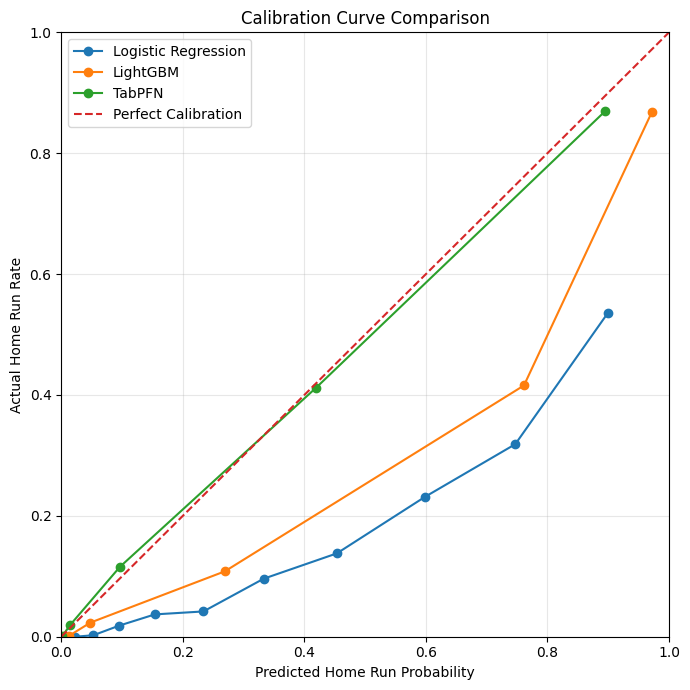

In [13]:
# Calibration 비교 대상 모델 정의
calibration_models = {
    "Logistic Regression": logit_test_proba,
    "LightGBM": lgbm_test_proba,
    "TabPFN": tabpfn_test_proba
}

# Calibration Curve 시각화
plt.figure(figsize=(7, 7))

for model_name, proba in calibration_models.items():
    prob_true, prob_pred = calibration_curve(
        y_test,
        proba,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=model_name
    )

# 완전 보정 기준선 추가
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

# 그래프 설정
plt.xlabel("Predicted Home Run Probability")
plt.ylabel("Actual Home Run Rate")
plt.title("Calibration Curve Comparison")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### **Phase 3: 변수 중요도 확인**

In [15]:
# TabPFN Calibration 기반 변수 중요도 계산 함수 정의
def calculate_calibration_importance(
    model,
    X_data,
    y_true,
    baseline_brier,
    n_repeats=5,
    chunk_size=2000,
    random_state=42
):
    results = []
    rng = np.random.default_rng(random_state)

    # 변수별 중요도 계산
    for feature in X_data.columns:
        scores = []

        # 반복별 변수 셔플 후 Brier Score 변화 측정
        for _ in range(n_repeats):
            X_permuted = X_data.copy()
            X_permuted[feature] = rng.permutation(X_permuted[feature].values)

            permuted_proba = predict_proba_in_chunks(
                model=model,
                X_data=X_permuted,
                chunk_size=chunk_size
            )

            permuted_brier = brier_score_loss(y_true, permuted_proba)
            scores.append(permuted_brier)

        # 변수 중요도 정리
        mean_brier = np.mean(scores)
        importance = mean_brier - baseline_brier

        results.append({
            "feature": feature,
            "importance": importance,
            "baseline_brier": baseline_brier,
            "permuted_brier": mean_brier
        })

    return pd.DataFrame(results).sort_values(
        "importance",
        ascending=False
    ).reset_index(drop=True)


# Validation 기준 baseline Brier Score 계산
tabpfn_baseline_brier = brier_score_loss(
    y_val,
    tabpfn_val_proba
)

# TabPFN Calibration 기반 변수 중요도 계산
tabpfn_calibration_importance_df = calculate_calibration_importance(
    model=tabpfn_model,
    X_data=X_val_tabpfn,
    y_true=y_val,
    baseline_brier=tabpfn_baseline_brier
)

# 변수 중요도 확인
tabpfn_calibration_importance_df

,feature,importance,baseline_brier,permuted_brier
0,launch_speed,0.106692,0.042839,0.149530
1,launch_angle,0.097272,0.042839,0.140111
2,spray_angle,0.033677,0.042839,0.076516
3,home_team,0.004269,0.042839,0.047108


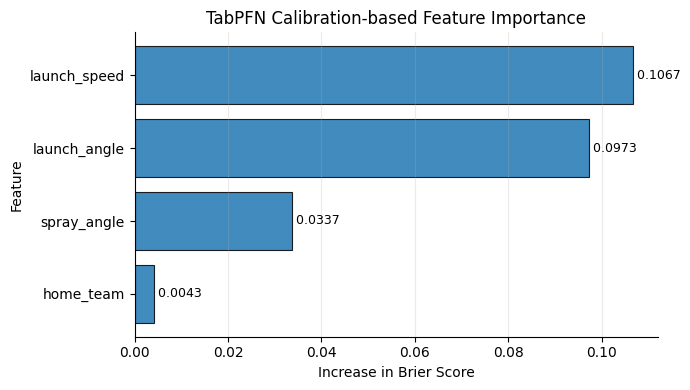

In [18]:
# TabPFN Calibration 기반 변수 중요도 시각화
fig, ax = plt.subplots(figsize=(7, 4))

# 변수 중요도 막대그래프 생성
bars = ax.barh(
    tabpfn_calibration_importance_df["feature"],
    tabpfn_calibration_importance_df["importance"],
    edgecolor="black",
    linewidth=0.8,
    alpha=0.85
)

# 변수 중요도 값 표시
for bar in bars:
    width = bar.get_width()
    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:.4f}",
        va="center",
        fontsize=9
    )

# 그래프 설정
ax.set_xlabel("Increase in Brier Score")
ax.set_ylabel("Feature")
ax.set_title("TabPFN Calibration-based Feature Importance")
ax.invert_yaxis()

# 그래프 디자인 정리
ax.grid(axis="x", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()